--- kNN Classification Results (k=1) ---
Total Test Samples: 1341

Correct Predictions: 1013
Wrong Predictions: 328
Overall Accuracy counted: 75.54%

---KNN K=1 Results---

Accuracy: 0.7554
Precision: 0.757425663837167
Recall   : 0.7554064131245339
F1 Score : 0.7560395867313914

Classification Report:
              precision    recall  f1-score   support

         cel       0.80      0.76      0.78        95
         cla       0.66      0.69      0.67        96
         flu       0.64      0.68      0.66        85
         gac       0.78      0.76      0.77       151
         gel       0.73      0.78      0.76       139
         org       0.90      0.85      0.88       145
         pia       0.76      0.80      0.78       142
         sax       0.66      0.65      0.65       114
         tru       0.81      0.77      0.79       119
         vio       0.66      0.65      0.65       109
         voi       0.82      0.82      0.82       146

    accuracy                           0.76    

<Figure size 1000x800 with 0 Axes>

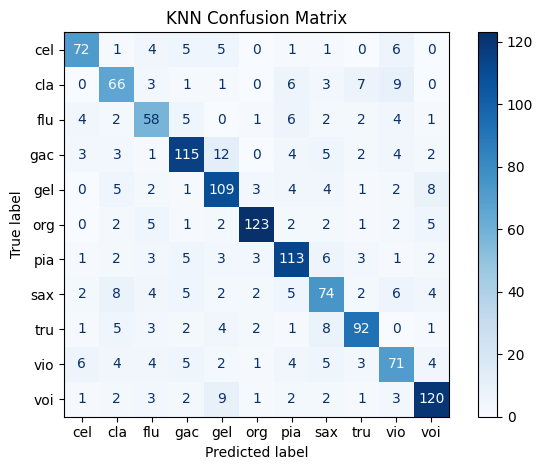

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split 
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1. Load the dataset
data=pd.read_csv(r"C:\Users\LENOVO\Documents\ML Project(Instrument Classifier)\Music Dataset.csv")
X = data.drop("Instrument",axis=1)
y = data["Instrument"]

# 2. Split the data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 3. Initialize the k-NN classifier (using k=1)
k = 1
knn = KNeighborsClassifier(n_neighbors=k)

# 4. Train the model
knn.fit(X_train, y_train)

# 5. Make predictions
y_pred = knn.predict(X_test)

# 6. Analyze and Print Results
print(f"--- kNN Classification Results (k={k}) ---")
print(f"Total Test Samples: {len(y_test)}\n")
correct_count = sum(1 for i in range(len(y_test)) if y_test.iloc[i] == y_pred[i])
wrong_count = len(y_test) - correct_count

accuracy = accuracy_score(y_test, y_pred) * 100
print(f"Correct Predictions: {correct_count}")
print(f"Wrong Predictions: {wrong_count}")
print(f"Overall Accuracy counted: {accuracy:.2f}%")

precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")
print(f"\n---KNN K=1 Results---\n")

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

conf_mat = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix")
print(conf_mat)

# 7. Display confusion matrix
plt.figure(figsize=(10, 8))
ConfusionMatrixDisplay(confusion_matrix=conf_mat, display_labels=knn.classes_).plot(cmap='Blues')
plt.title('KNN Confusion Matrix')
plt.tight_layout()
plt.show()

Test with 13
range(1, 26)
[0.6778523489932886, 0.575689783743475, 0.5503355704697986, 0.5361670395227442, 0.5249813571961223, 0.5033557046979866, 0.5041014168530947, 0.49217002237136465, 0.4906785980611484, 0.48396718866517524, 0.4802386278896346, 0.4727815063385533, 0.4727815063385533, 0.46234153616703955, 0.4615958240119314, 0.45786726323639076, 0.4563758389261745, 0.46308724832214765, 0.46308724832214765, 0.4526472781506339, 0.4541387024608501, 0.4444444444444444, 0.44146159582401195, 0.43400447427293065, 0.4354958985831469]


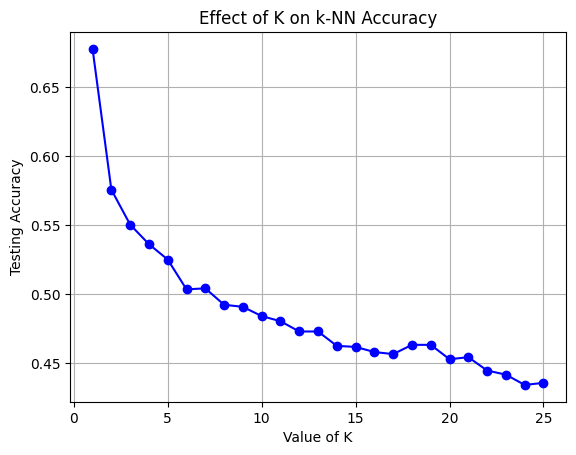

In [8]:
# 1. Load data
data=pd.read_csv(r"C:\course\sem 4\ml Project\Music Dataset.csv")
X = data.iloc[:, :13]
print("Test with 13")
y = data["Instrument"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 2. Test different K values
k_range = range(1, 26)
scores = []
for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    scores.append(accuracy_score(y_test, knn.predict(X_test)))

# 3. Plot the results
print(k_range)
print(scores)
plt.plot(k_range, scores, marker='o', linestyle='-', color='blue')
plt.title('Effect of K on k-NN Accuracy')
plt.xlabel('Value of K')
plt.ylabel('Testing Accuracy')
plt.grid(True)
plt.savefig('knn_accuracy_plot.png')

In [6]:
# Try using only the first 13 columns



import pandas as pd
from sklearn.model_selection import train_test_split 
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1. Load the dataset
data=pd.read_csv(r"C:\course\sem 4\ml Project\Music Dataset.csv")
X = data.iloc[:, :13]
y = data["Instrument"]

# 2. Split the data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 3. Initialize the k-NN classifier (using k=3)
k = 3
knn = KNeighborsClassifier(n_neighbors=k)

# 4. Train the model
knn.fit(X_train, y_train)

# 5. Make predictions
y_pred = knn.predict(X_test)

# 6. Analyze and Print Results
print(f"--- kNN Classification Results (k={k}) ---")
print(f"Total Test Samples: {len(y_test)}\n")
correct_count = 0
wrong_count = 0

for i in range(len(y_test)):
    actual = y_test.iloc[i]
    predicted = y_pred[i]
    if actual == predicted:
        correct_count += 1
    else:
        wrong_count += 1


# 7. Final Summary
accuracy = accuracy_score(y_test, y_pred) * 100
print(f"Correct Predictions: {correct_count}")
print(f"Wrong Predictions: {wrong_count}")
print(f"Overall Accuracy counted: {accuracy:.2f}%")



precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")
print(f"\n---KNN K={k} Results---\n")

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

--- kNN Classification Results (k=3) ---
Total Test Samples: 1341

Correct Predictions: 738
Wrong Predictions: 603
Overall Accuracy counted: 55.03%

---KNN K=3 Results---

Accuracy: 0.5503
Precision: 0.5701031008842371
Recall   : 0.5503355704697986
F1 Score : 0.5516408131591835

Confusion Matrix
[[ 63   4   4   3   7   3   6   1   1   3   0]
 [  5  56   1   7   1   2  10   4   5   4   1]
 [ 12  14  36   7   1   3   7   1   1   1   2]
 [  2   6  11 102   9   2   6   5   2   3   3]
 [  5   3   5  10  87   4   3   4   5   4   9]
 [  1   5  15   6  14  86   4   5   2   4   3]
 [  8  10  11  12   7   4  83   4   2   0   1]
 [  7  13   4   6   7   5   8  48   5   7   4]
 [  8  16   6   4   9   1   5   7  57   3   3]
 [ 14   4   6  11   6   6   4   3   4  45   6]
 [  5   4   9  14  17   9   2   7   2   2  75]]
